# Experiment 4 — MovieLens prototypes: kabc's decision rule vs. unif-kkm's k-means under real imbalance

Figures per `docs/experiments.md`, Experiment 4 section. This notebook only loads `results/exp4_{baseline,amplified_imbalance}/results.parquet` and plots — it never recomputes any algorithm's result (see CLAUDE.md and `docs/experiments.md` §0.4). Run `python -m scripts.run_experiment4` to generate them.

**Clean redesign (2026-09-16)**, replacing the earlier 4-condition/6-algorithm version entirely. Two algorithms only (`kabc`, `unif-kkm-1x`, matched-budget), two settings, both real-data mean-gap-resampled every rep (no hand-picked fixed instance):
- **`baseline`**: K=7, same role/count structure as the earlier design's `resampled` condition, `budget_cap` raised to clear k=8's full cumulative cost.
- **`amplified_imbalance`**: K=12, a much more skewed far-pair ratio (20:2, not 12:2) — the regime where the earlier design's `track_a` showed the cleanest imbalance-specific signal, stressed harder.

Both settings run at `n_jobs=5` with a real-verified memory-guard override (not just the relaxed formula — see `docs/experiments.md`'s "Memory guard override" note for the exact measured peak RSS, the 5-concurrent-worker test, and the `vm_stat` swap check) that raises kabc's honest convergence ceiling from k≤7 to k≤8.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

sys.path.insert(0, "..")
from kabc.plotting import set_style, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS

set_style()

SETTINGS = ["baseline", "amplified_imbalance"]
SETTING_TITLES = {
    "baseline": "baseline (K=7, far 12:2, close/far mean-gap-resampled every rep)",
    "amplified_imbalance": "amplified_imbalance (K=12, far 20:2, same resampling mechanism)",
}

dfs = {}
for setting in SETTINGS:
    path = Path(f"../results/exp4_{setting}/results.parquet")
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run `python -m scripts.run_experiment4` to generate it -- "
            "this notebook only plots existing results, it never recomputes them."
        )
    dfs[setting] = pd.read_parquet(path)
    print(f"loaded {len(dfs[setting])} rows ({dfs[setting]['rep'].nunique()} reps) from {path}")

dfs["baseline"].head()

loaded 100 rows (50 reps) from ../results/exp4_baseline/results.parquet
loaded 100 rows (50 reps) from ../results/exp4_amplified_imbalance/results.parquet


,exp_id,setting,algorithm,rep,seed,N,K,budget_cap,tau,stopped,wall_clock_seconds,partition,error,ari,ari_close_pair,ari_far_pair,misclass_rate_large,misclass_rate_small,n_iterations,close_a_movie_id,close_b_movie_id,close_a_title,close_b_title,close_mean_gap,far_large_movie_id,far_small_movie_id,far_large_title,far_small_title,far_mean_gap
0,4,baseline,kabc,0,4000100,40,7,400000,360720,False,1604.884510,"[0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, ...",1,0.990654,1.00,1.000000,0.000000,0.111111,9,2396,2959,Shakespeare in Love (1998),Fight Club (1999),0.050292,2302,1917,My Cousin Vinny (1992),Armageddon (1998),0.592638
1,4,baseline,unif-kkm-1x,0,4000101,40,7,360720,360720,True,5.824859,"[6, 6, 5, 6, 6, 5, 5, 5, 5, 4, 0, 0, 0, 0, 0, ...",1,0.700913,0.55,0.553484,0.258065,0.000000,0,2396,2959,Shakespeare in Love (1998),Fight Club (1999),0.050292,2302,1917,My Cousin Vinny (1992),Armageddon (1998),0.592638
2,4,baseline,kabc,1,4001100,40,7,400000,360720,True,1606.126522,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, ...",1,0.907913,0.00,0.972077,0.000000,0.555556,8,3147,1200,"Green Mile, The (1999)",Aliens (1986),0.028840,2081,593,"Little Mermaid, The (1989)","Silence of the Lambs, The (1991)",0.595301
3,4,baseline,unif-kkm-1x,1,4001101,40,7,360720,360720,True,5.709855,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 6, 0, 6, 0, 6, ...",1,0.571381,0.00,0.299563,0.258065,0.555556,0,3147,1200,"Green Mile, The (1999)",Aliens (1986),0.028840,2081,593,"Little Mermaid, The (1989)","Silence of the Lambs, The (1991)",0.595301
4,4,baseline,kabc,2,4002100,40,7,400000,360720,True,1602.822616,"[0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, ...",0,1.000000,1.00,1.000000,0.000000,0.000000,8,2321,1653,Pleasantville (1998),Gattaca (1997),0.014344,1704,380,Good Will Hunting (1997),True Lies (1994),0.542071


## Headline figure: real rating histograms for rep=0's prototypes, one bar plot per setting

Real rating histograms (`data/ml-1m-207/ratings.parquet`, not recomputed from any algorithm output — same category as notebook 03's own headline figure) for the movies actually drawn at `rep=0`. Both settings resample every rep, so this is one real, actual draw, not a fixed illustration. Close/far pair identities are logged per-row (`close_a_movie_id`, etc.); the generic anchors are not (kept out of the results schema to keep it small), so they are re-derived here by calling the exact same deterministic, seeded selection function the real run used (`scripts.run_experiment4._choose_resampled_prototypes`, same `rep_seed`) — a lookup, not a recompute of any algorithm result, verified below against the logged designated-pair fields.

In [2]:
sys.path.insert(0, "../")
from scripts.run_experiment4 import _load_movie_pool, _choose_resampled_prototypes

with open("../configs/exp4.yaml") as f:
    exp4_config = yaml.safe_load(f)

ratings = pd.read_parquet("../data/ml-1m-207/ratings.parquet")
movie_ids, means, titles, pools, mmd2 = _load_movie_pool(Path("..") / exp4_config["data_dir"])

HEADLINE_REP = 0
REP_SEED = exp4_config["seed_multiplier"] * exp4_config["exp_id"] + HEADLINE_REP

PROTOTYPES_BY_SETTING = {}
for setting in SETTINGS:
    env, roles, pair_info = _choose_resampled_prototypes(
        exp4_config["conditions"][setting], REP_SEED, movie_ids, means, titles, pools,
    )
    protos = [
        {"movie_id": mid, "title": titles[mid], "role": role, "count": count}
        for mid, role, count in zip(env.movie_ids, roles, env.counts)
    ]
    PROTOTYPES_BY_SETTING[setting] = protos

    # sanity check: re-derived designated-pair identities must match what the
    # real run actually logged for rep=0 -- confirms the lookup is exact
    logged = dfs[setting][dfs[setting]["rep"] == HEADLINE_REP].iloc[0]
    derived_by_role = {p["role"]: p["movie_id"] for p in protos}
    assert derived_by_role["close_a"] == logged["close_a_movie_id"]
    assert derived_by_role["close_b"] == logged["close_b_movie_id"]
    assert derived_by_role["far_large"] == logged["far_large_movie_id"]
    assert derived_by_role["far_small"] == logged["far_small_movie_id"]
    print(f"{setting}: re-derived rep=0 role assignment matches the logged designated pairs exactly")
    for p in protos:
        print(f"  [{p['movie_id']}] {p['title']:35s} role={p['role']:12s} n={p['count']}")

baseline: re-derived rep=0 role assignment matches the logged designated pairs exactly
  [2396] Shakespeare in Love (1998)          role=close_a      n=5
  [2959] Fight Club (1999)                   role=close_b      n=4
  [2302] My Cousin Vinny (1992)              role=far_large    n=12
  [1917] Armageddon (1998)                   role=far_small    n=2
  [1252] Chinatown (1974)                    role=generic_1    n=8
  [1676] Starship Troopers (1997)            role=generic_2    n=6
  [1101] Top Gun (1986)                      role=generic_3    n=3
amplified_imbalance: re-derived rep=0 role assignment matches the logged designated pairs exactly
  [2396] Shakespeare in Love (1998)          role=close_a      n=5
  [2959] Fight Club (1999)                   role=close_b      n=4
  [2302] My Cousin Vinny (1992)              role=far_large    n=20
  [1917] Armageddon (1998)                   role=far_small    n=2
  [1676] Starship Troopers (1997)            role=generic_1    n=10
  [356] 

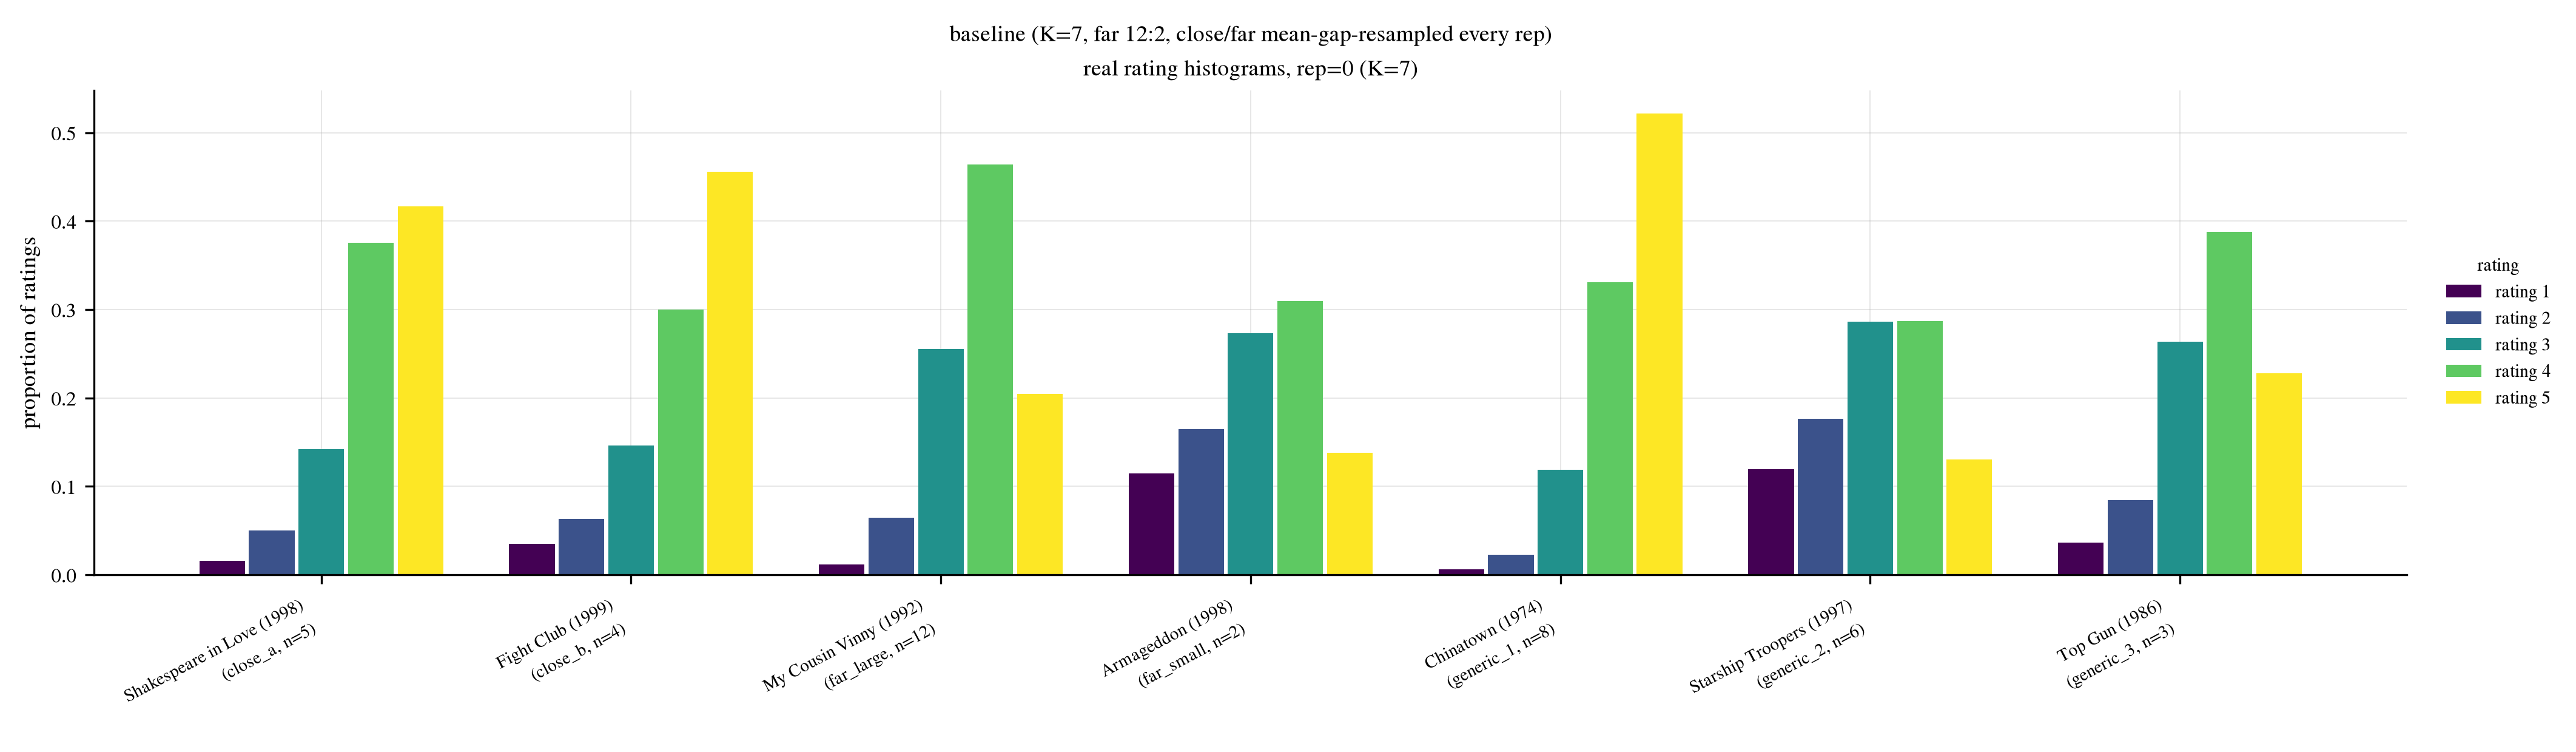

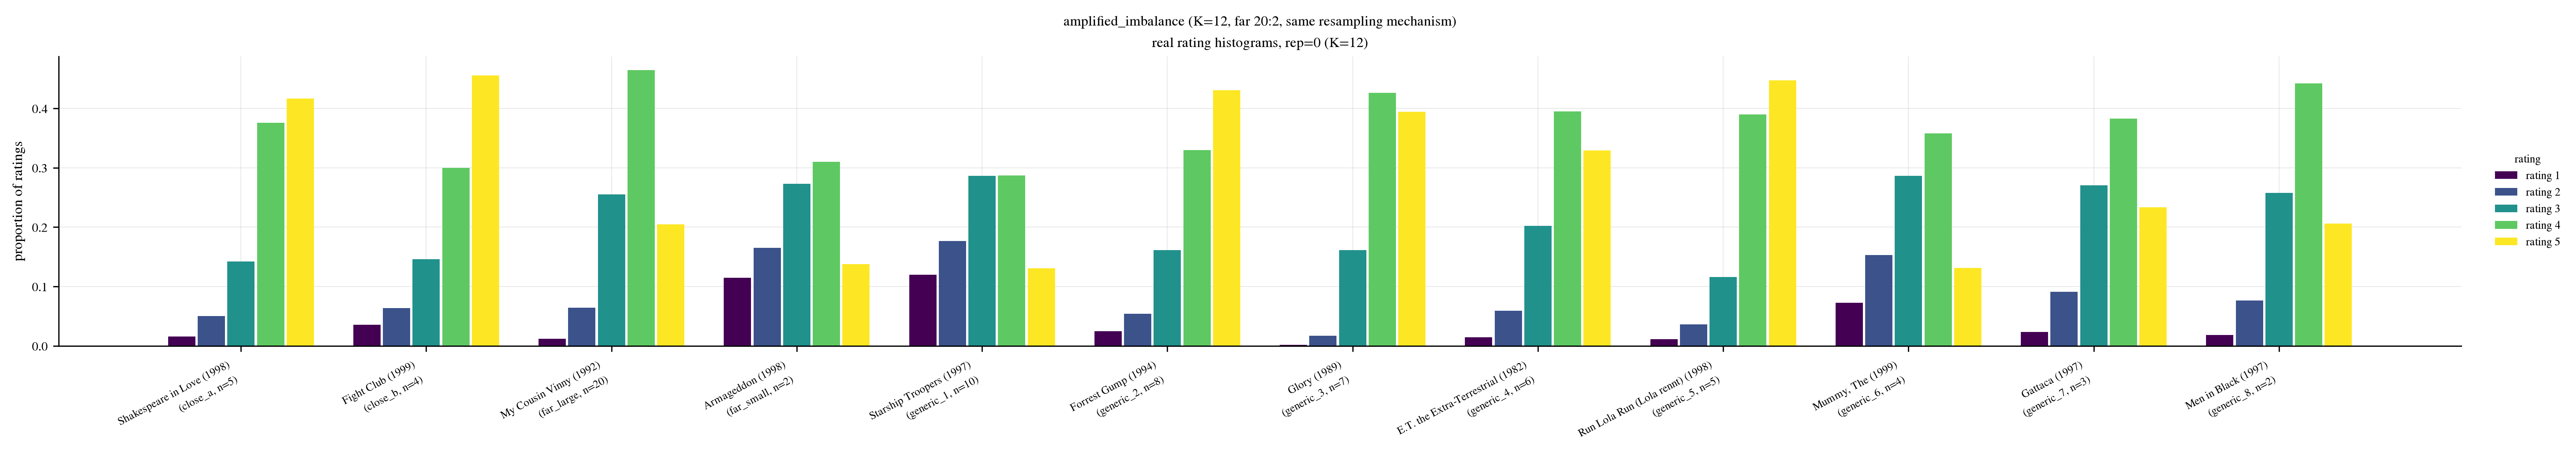

In [3]:
RATING_VALUES = [1, 2, 3, 4, 5]
RATING_COLORS = [plt.cm.viridis(i / 4) for i in range(5)]


def plot_prototype_histograms(setting: str, prototypes: list[dict], fig_name: str):
    K = len(prototypes)
    fig, ax = plt.subplots(figsize=(1.7 * K + 2.3, 4.2))
    bar_width = 0.8 / len(RATING_VALUES)
    x_base = np.arange(K)

    for r_idx, rating in enumerate(RATING_VALUES):
        heights = []
        for p in prototypes:
            pool = ratings.loc[ratings["movie_id"] == p["movie_id"], "rating"]
            heights.append(float((pool == rating).mean()))
        offset = (r_idx - (len(RATING_VALUES) - 1) / 2) * bar_width
        ax.bar(x_base + offset, heights, bar_width * 0.92, color=RATING_COLORS[r_idx],
               label=f"rating {rating}")

    ax.set_xticks(x_base)
    labels = [f"{p['title']}\n({p['role']}, n={p['count']})" for p in prototypes]
    ax.set_xticklabels(labels, rotation=28, ha="right", fontsize=7)
    ax.set_ylabel("proportion of ratings")
    ax.set_title(f"{SETTING_TITLES[setting]}\nreal rating histograms, rep={HEADLINE_REP} (K={K})", fontsize=9)
    ax.legend(title="rating", fontsize=7, title_fontsize=7, frameon=False,
              loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


for setting in SETTINGS:
    plot_prototype_histograms(setting, PROTOTYPES_BY_SETTING[setting], f"exp4_fig0_histograms_{setting}")

## Instance structure at a glance: arm counts, pairwise mean separation, pairwise MMD², one 3-panel figure per setting

An alternative, more compact view of the same rep=0 instances as the histograms above: for each setting, (1) a bar plot of arms-per-prototype (movie titles in the legend, not the x-axis, to keep it readable), (2) a K×K heatmap of pairwise mean-rating separation $|\bar\mu_i-\bar\mu_j|$, (3) a K×K heatmap of pairwise MMD². Both heatmaps are computed directly from the real per-movie rating pools (`data/ml-1m-207/ratings.parquet`) and the shared 207-movie MMD² matrix already loaded above (`compute_pairwise_mmd2`) — not recomputed from any algorithm output. Axis ticks use the short role labels (`close_a`, `far_large`, `generic_1`, ...); the legend on the bar plot maps each role to its real movie title, shared across all three panels since the prototype identity/order is the same in each.

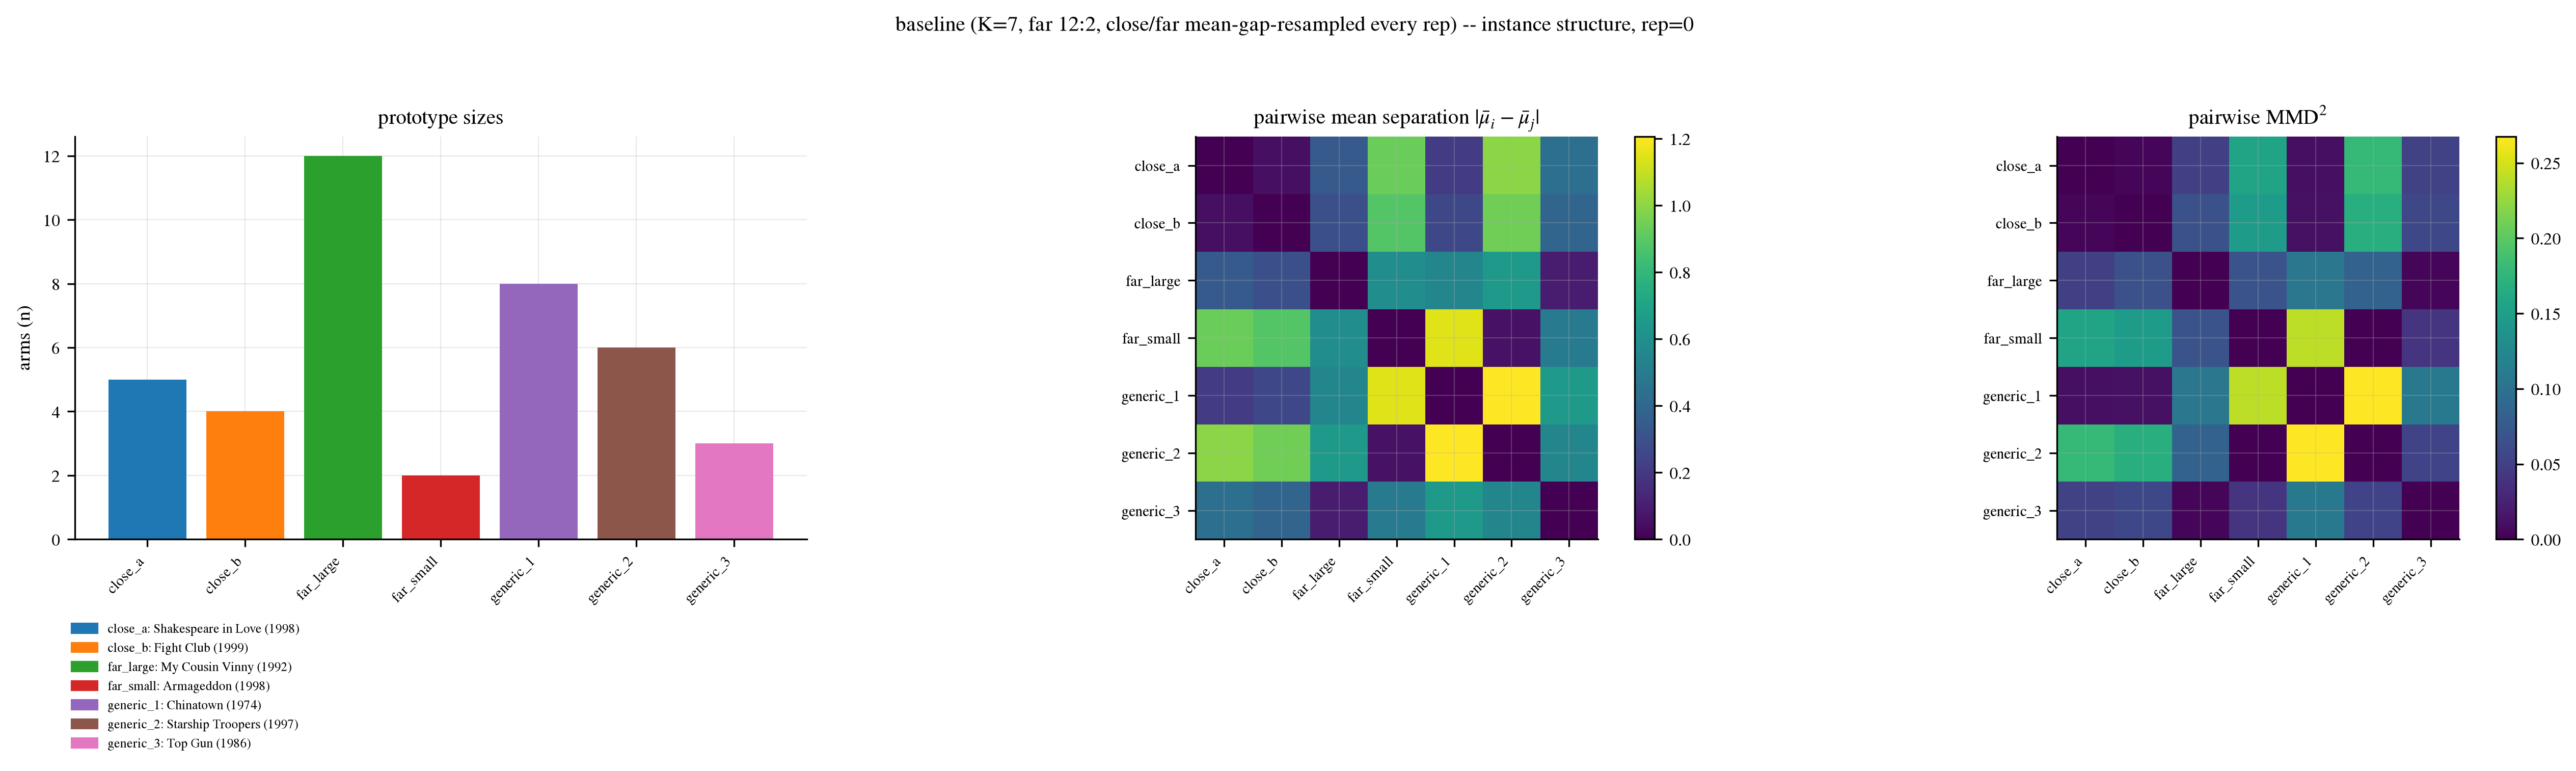

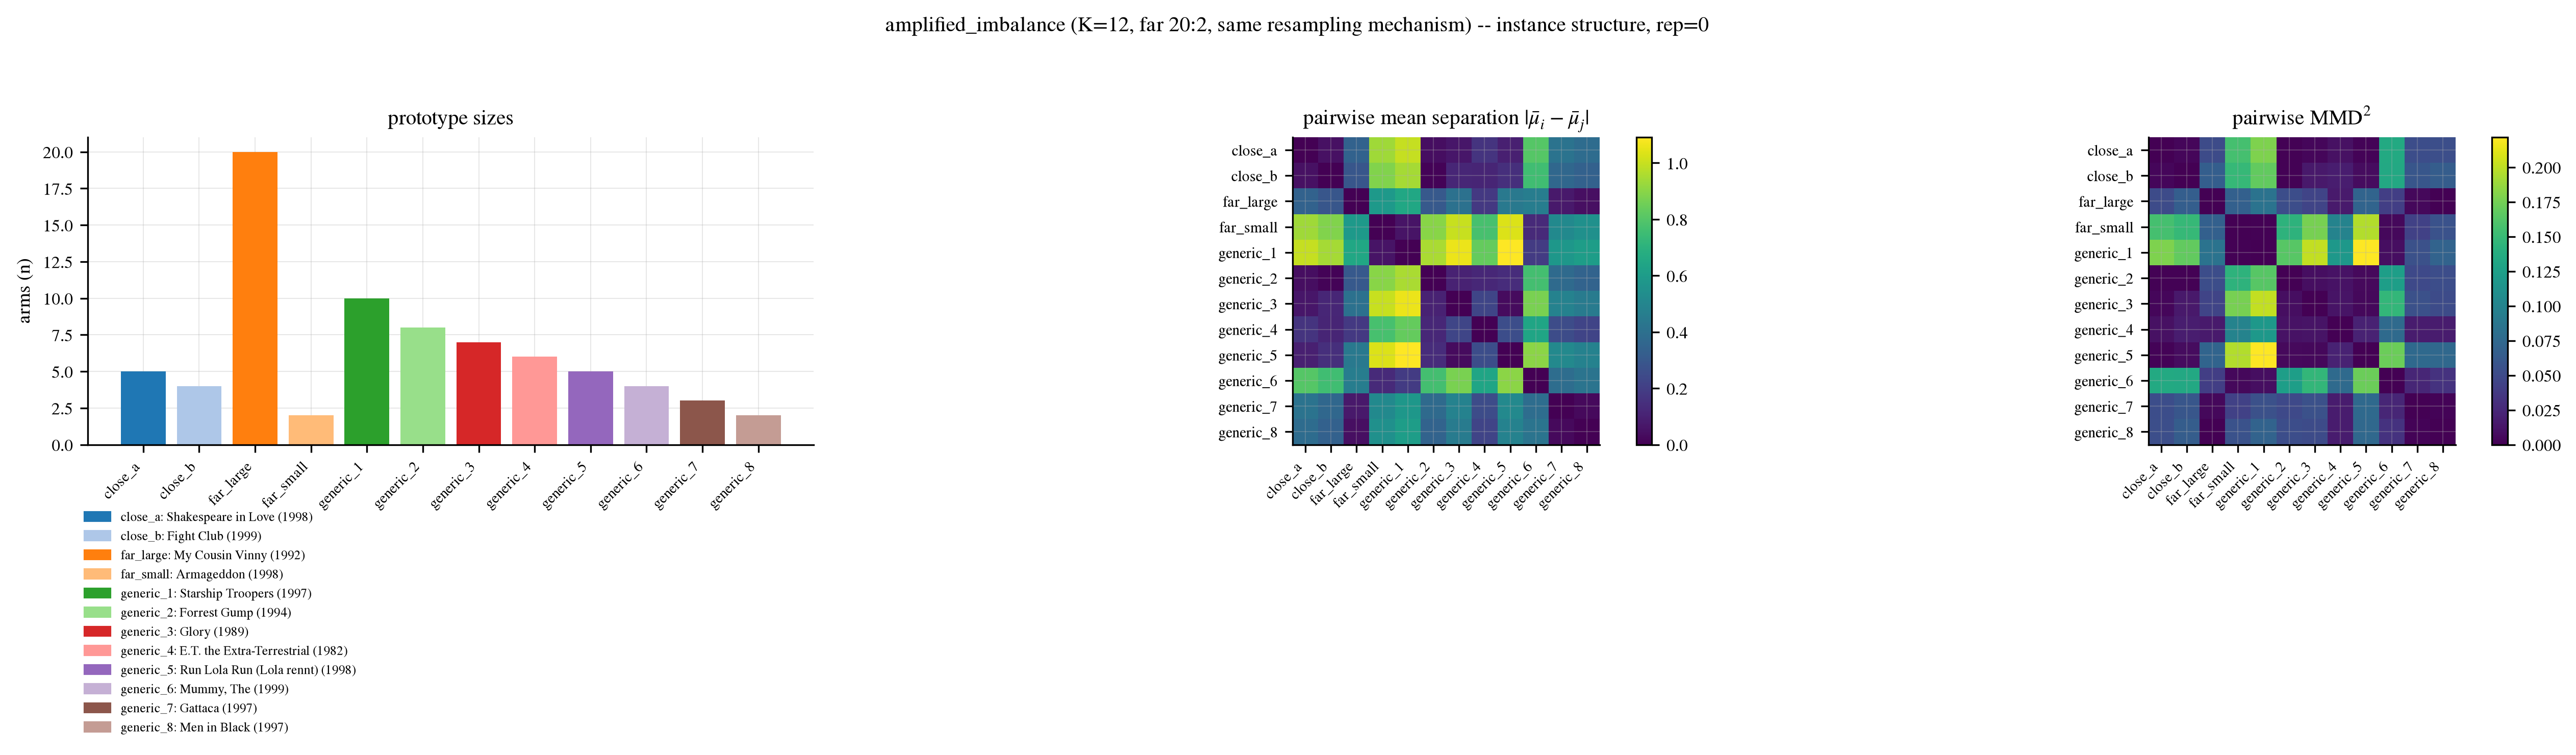

In [4]:
id2idx_global = {mid: i for i, mid in enumerate(movie_ids)}


def plot_instance_overview(setting: str, prototypes: list[dict], fig_name: str):
    K = len(prototypes)
    counts = [p["count"] for p in prototypes]
    roles = [p["role"] for p in prototypes]
    proto_titles = [p["title"] for p in prototypes]
    proto_movie_ids = [p["movie_id"] for p in prototypes]

    mean_vals = np.array([means[id2idx_global[mid]] for mid in proto_movie_ids])
    mean_gap = np.abs(mean_vals[:, None] - mean_vals[None, :])

    global_idx = [id2idx_global[mid] for mid in proto_movie_ids]
    mmd2_sub = mmd2[np.ix_(global_idx, global_idx)].copy()
    np.fill_diagonal(mmd2_sub, 0.0)  # diagonal is -inf by convention (self mmd2 undefined); 0 reads cleanly on the heatmap

    cmap_bars = plt.cm.tab20 if K > 10 else plt.cm.tab10
    bar_colors = [cmap_bars(i % cmap_bars.N) for i in range(K)]

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    ax0 = axes[0]
    ax0.bar(range(K), counts, color=bar_colors)
    ax0.set_xticks(range(K))
    ax0.set_xticklabels(roles, rotation=45, ha="right", fontsize=7)
    ax0.set_ylabel("arms (n)")
    ax0.set_title("prototype sizes")
    handles = [plt.Rectangle((0, 0), 1, 1, color=bar_colors[i]) for i in range(K)]
    ax0.legend(handles, [f"{r}: {t}" for r, t in zip(roles, proto_titles)], fontsize=6,
               loc="upper left", bbox_to_anchor=(-0.02, -0.18), frameon=False, ncol=1)

    ax1 = axes[1]
    im1 = ax1.imshow(mean_gap, cmap="viridis")
    ax1.set_xticks(range(K)); ax1.set_xticklabels(roles, rotation=45, ha="right", fontsize=7)
    ax1.set_yticks(range(K)); ax1.set_yticklabels(roles, fontsize=7)
    ax1.set_title(r"pairwise mean separation $|\bar\mu_i-\bar\mu_j|$")
    fig.colorbar(im1, ax=ax1, fraction=0.046)

    ax2 = axes[2]
    im2 = ax2.imshow(mmd2_sub, cmap="viridis")
    ax2.set_xticks(range(K)); ax2.set_xticklabels(roles, rotation=45, ha="right", fontsize=7)
    ax2.set_yticks(range(K)); ax2.set_yticklabels(roles, fontsize=7)
    ax2.set_title(r"pairwise MMD$^2$")
    fig.colorbar(im2, ax=ax2, fraction=0.046)

    fig.suptitle(f"{SETTING_TITLES[setting]} -- instance structure, rep={HEADLINE_REP}", y=1.04, fontsize=10)
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


for setting in SETTINGS:
    plot_instance_overview(setting, PROTOTYPES_BY_SETTING[setting], f"exp4_fig0b_instance_overview_{setting}")

## kabc's convergence rate and budget ($\tau$), one table (no plot), both settings

In [5]:
rows = []
for setting in SETTINGS:
    sub = dfs[setting][dfs[setting]["algorithm"] == "kabc"]
    rows.append({
        "setting": setting,
        "K": sub["K"].iloc[0] if "K" in sub else np.nan,
        "N": sub["N"].iloc[0] if "N" in sub else np.nan,
        "budget_cap": sub["budget_cap"].iloc[0],
        "n_reps": sub["rep"].nunique(),
        "convergence_rate": sub["stopped"].mean(),
        "std_convergence_rate": sub["stopped"].std(),
        "mean_tau": sub["tau"].mean(),
        "std_tau": sub["tau"].std(),
        "mean_ari": sub["ari"].mean(),
    })
kabc_table = pd.DataFrame(rows)
kabc_table

,setting,K,N,budget_cap,n_reps,convergence_rate,std_convergence_rate,mean_tau,std_tau,mean_ari
0,baseline,7,40,400000,50,0.66,0.478518,285492.00,113719.404407,0.964319
1,amplified_imbalance,12,76,800000,50,0.32,0.471212,705535.36,102742.605985,0.912778


## kabc: mean ARI split by stopped status

Naive blended ARI (the table above and the bar plot below) mixes `stopped=True` and `stopped=False` (capped, graceful near-miss) reps — this matches the established convention across notebooks 01-03 (no `stopped`-conditioned split there either) and `docs/experiments.md`'s own stated policy that capped-run ARI is real diagnostic signal, not noise to discard. Shown separately here so the blend is never opaque. `unif-kkm-1x` has no `stopped=False` rows (`baselines.fit` has no stopping rule — it always completes).

In [6]:
for setting in SETTINGS:
    print(f"=== {setting} ===")
    display(dfs[setting].groupby(["algorithm", "stopped"])["ari"].agg(["mean", "std", "count"]).round(3))

=== baseline ===
=== amplified_imbalance ===


mean    std  count
algorithm   stopped                     
kabc        False    0.950  0.062     17
            True     0.972  0.057     33
unif-kkm-1x True     0.668  0.148     50

mean    std  count
algorithm   stopped                     
kabc        False    0.900  0.093     34
            True     0.940  0.049     16
unif-kkm-1x True     0.489  0.079     50

## ARI comparison: kabc vs. unif-kkm-1x, one bar plot with 2 sets

One grouped bar plot: 2 sets (one per setting), each set showing both algorithm rows — mean ARI $\pm$ std over reps, same `grouped_bar_plot` convention as notebook 03.

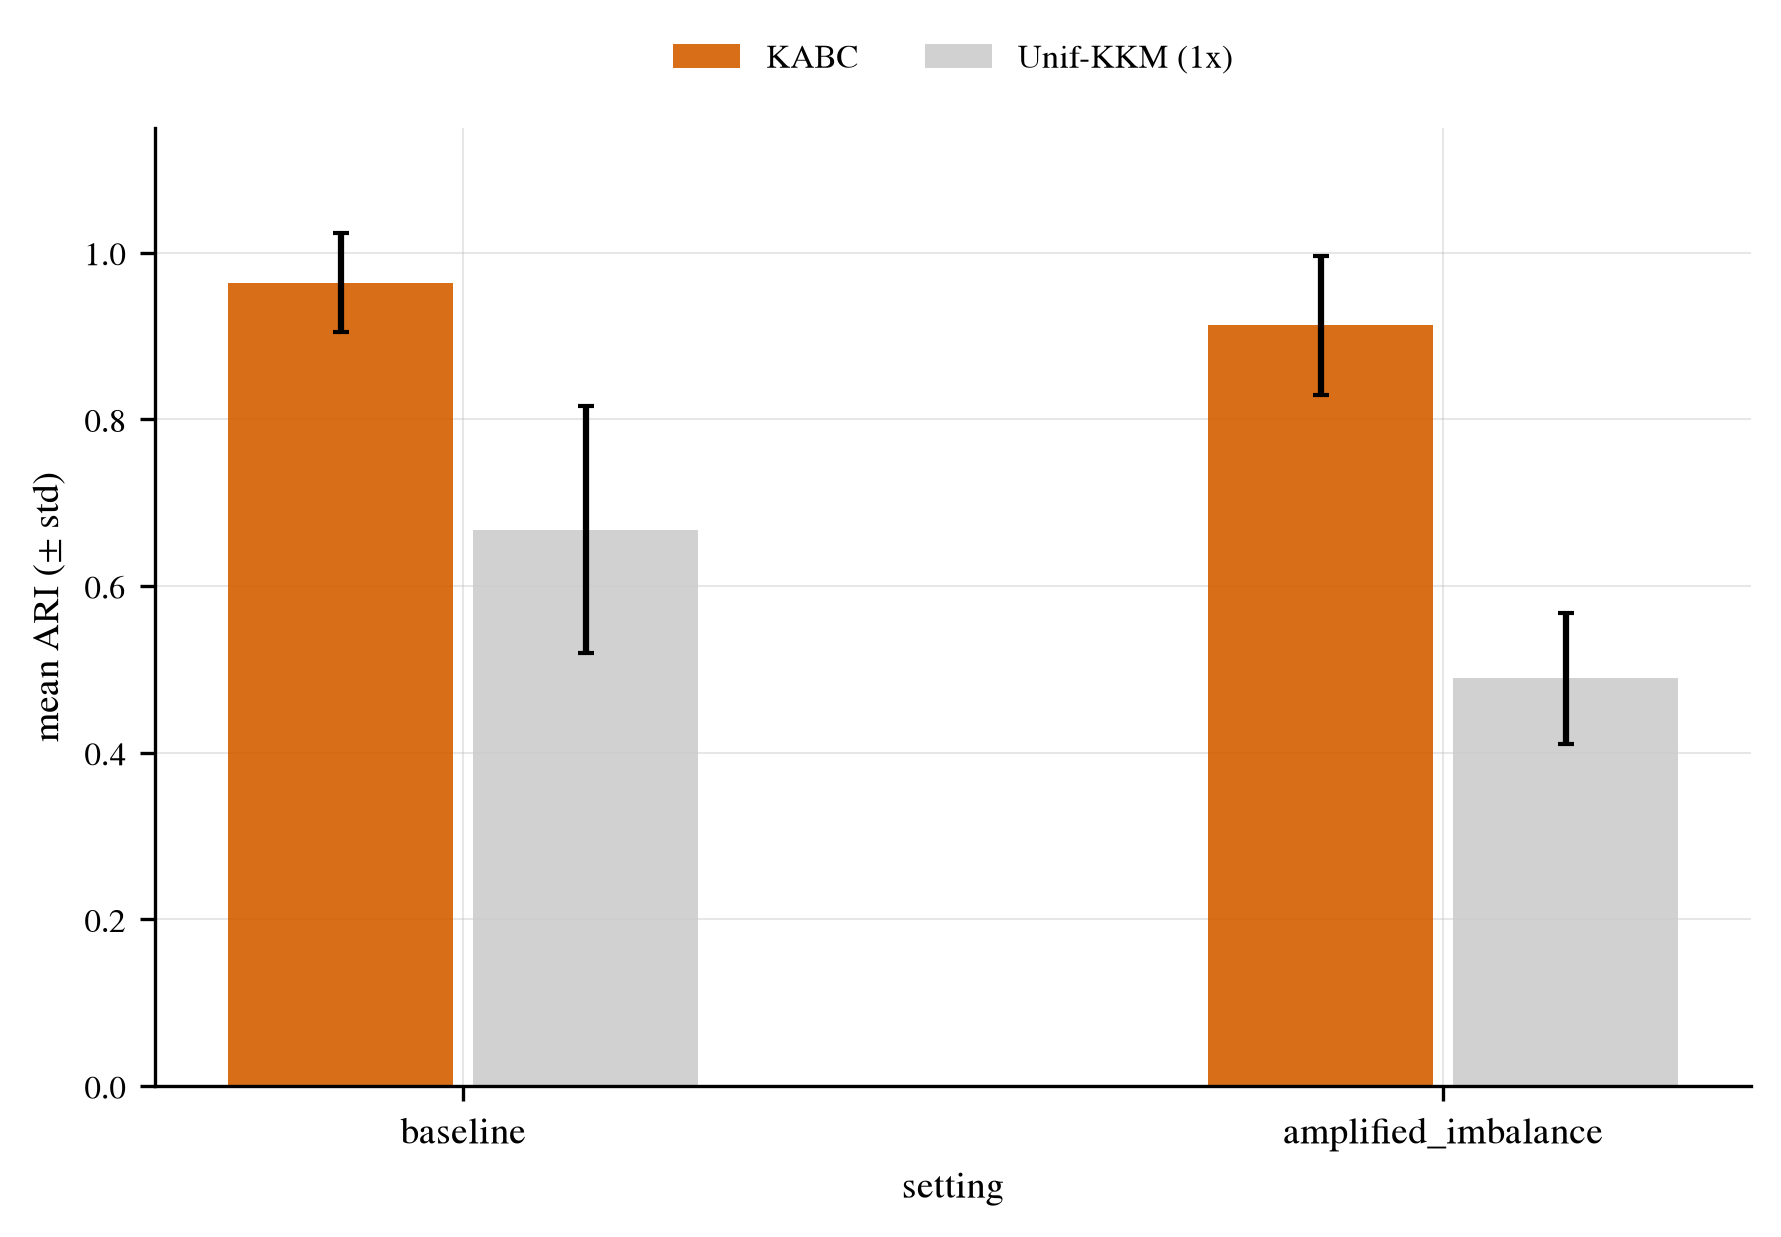

In [7]:
ALGOS = [a for a in ALGO_ORDER if a in dfs["baseline"]["algorithm"].unique()]
assert len(ALGOS) == 2, f"expected 2 algorithm rows, got {len(ALGOS)}: {ALGOS}"

n_algo = len(ALGOS)
bar_width = 0.8 / n_algo
group_gap = 0.6

fig, ax = plt.subplots(figsize=(6, 4.2))
xtick_positions, xtick_labels = [], []
for s_idx, setting in enumerate(SETTINGS):
    df = dfs[setting]
    group_center = s_idx * (1.0 + group_gap)
    for a_idx, algo in enumerate(ALGOS):
        sub = df[df["algorithm"] == algo]
        mean = sub["ari"].mean()
        std = sub["ari"].std()
        x = group_center + (a_idx - (n_algo - 1) / 2) * bar_width
        ax.bar(x, mean, yerr=std, width=bar_width * 0.92, capsize=2,
               color=ALGO_COLORS[algo], alpha=0.9,
               label=ALGO_LABELS[algo] if s_idx == 0 else None)
    xtick_positions.append(group_center)
    xtick_labels.append(setting)

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=9)
ax.set_xlabel("setting")
ax.set_ylabel("mean ARI (± std)")
ax.set_ylim(0, 1.15)
ax.legend(fontsize=8, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.12))
fig.tight_layout()
savefig(fig, "exp4_fig1_ari_bars", fig_dir="../results/figures")
plt.show()

## Close/far pair ARI and large/small misclassification breakdown, by setting and algorithm

Carried over unchanged from the earlier design (both were essential to interpreting `track_a`'s and `resampled`'s results there): `ari_close_pair`/`ari_far_pair` isolate the closeness vs. imbalance effect; `misclass_rate_large`/`misclass_rate_small` directly test whether small prototypes are misclassified more often.

In [8]:
for setting in SETTINGS:
    print(f"=== {setting}: ari_close_pair vs ari_far_pair ===")
    display(dfs[setting].groupby("algorithm")[["ari_close_pair", "ari_far_pair"]].agg(["mean", "std"]).round(3))
    print(f"=== {setting}: misclass_rate_large vs misclass_rate_small ===")
    display(dfs[setting].groupby("algorithm")[["misclass_rate_large", "misclass_rate_small"]].agg(["mean", "std"]).round(3))

=== baseline: ari_close_pair vs ari_far_pair ===
=== baseline: misclass_rate_large vs misclass_rate_small ===
=== amplified_imbalance: ari_close_pair vs ari_far_pair ===
=== amplified_imbalance: misclass_rate_large vs misclass_rate_small ===


ari_close_pair        ari_far_pair       
                      mean    std         mean    std
algorithm                                            
kabc                 0.927  0.237        0.990  0.039
unif-kkm-1x          0.568  0.401        0.526  0.267

misclass_rate_large        misclass_rate_small       
                           mean    std                mean    std
algorithm                                                        
kabc                      0.010  0.039               0.116  0.154
unif-kkm-1x               0.216  0.113               0.249  0.200

ari_close_pair        ari_far_pair       
                      mean    std         mean    std
algorithm                                            
kabc                 0.903  0.248        0.994  0.034
unif-kkm-1x          0.482  0.339        0.201  0.076

misclass_rate_large        misclass_rate_small       
                           mean    std                mean    std
algorithm                                                        
kabc                      0.052  0.065               0.223  0.198
unif-kkm-1x               0.362  0.066               0.427  0.147